# Decision Tree Classifiers

**Author:** Ahmet Emre Küçükatay

**Date:** October 2026

**Email**: ahmet.kucukatay@sabanciuniv.edu

In [ ]:
# Make sure you have these libraries
#!pip install matplotlib
#!pip install scikit-learn

## Information About Decision Tree Classifiers



*   A supervised learning algorithm that uses a tree-like structure consisting of a root node, internal nodes, branches, and leaf nodes.
*   Each internal node represents a test on a feature, each branch a decision outcome, and each leaf a predicted label or value.
*   Decision trees are built recursively by selecting a feature and splitting the training samples into smaller subsets.
*   The choice of a split can be based on impurity measures such as entropy, gini-index or misclassification error
* Increasing the complexity of a decision tree can improve its fit to the training data, but may also lead to overfitting.

## Choosing a Split: Entropy and Information Gain

When building a decision tree, we need to decide which feature should be used to split the samples at each node.

One way to evaluate a candidate split is by using **entropy**.

* Entropy measures the uncertainty or impurity in a set of samples.
* A node containing samples from only one class has low entropy.
* A node containing a mixture of classes has higher entropy.
* A good split reduces the uncertainty in the resulting child nodes.

The reduction in entropy obtained by a split is called **information gain**.

In [1]:
import pandas as pd
import numpy as np

data = {
    "Weather": ["Sunny", "Sunny", "Rainy", "Rainy", "Cloudy", "Cloudy"],
    "Wind": ["Weak", "Strong", "Weak", "Strong", "Weak", "Strong"],
    "Play": ["Yes", "No", "Yes", "No", "Yes", "Yes"]
}

df = pd.DataFrame(data)
df

,Weather,Wind,Play
0,Sunny,Weak,Yes
1,Sunny,Strong,No
2,Rainy,Weak,Yes
3,Rainy,Strong,No
4,Cloudy,Weak,Yes
5,Cloudy,Strong,Yes


### Entropy Calculation

For our dataset, the target variable **Play** contains:

- 4 "Yes" samples
- 2 "No" samples

The entropy of the parent node is calculated as:

$$
H(S) = -p_{\text{Yes}}\log_2(p_{\text{Yes}})
       -p_{\text{No}}\log_2(p_{\text{No}})
$$

For our dataset:

$$
H(S) =
-\frac{4}{6}\log_2\left(\frac{4}{6}\right)
-\frac{2}{6}\log_2\left(\frac{2}{6}\right)
\approx 0.918
$$

Now, let's implement this calculation as a function.

In [2]:
def entropy(labels):
    _, counts = np.unique(labels, return_counts=True)

    probabilities = counts / len(labels)

    print(probabilities)
    return -np.sum(probabilities * np.log2(probabilities))

parent_entropy = entropy(df["Play"])

print(f"Parent Entropy: {parent_entropy:.3f}")

[0.33333333 0.66666667]
Parent Entropy: 0.918


### Information Gain Calculation

For a candidate split, we first calculate the weighted entropy of the resulting child nodes:

$$
\text{Remaining Entropy}
=
\sum
\frac{|S_v|}{|S|}
H(S_v)
$$

Information gain is then calculated as:

$$
IG(S,A)
=
H(S)
-
\text{Remaining Entropy}
$$

Here, $|S_v|/|S|$ represents the proportion of samples that fall into a particular child node.

A split with a **higher information gain** is preferred.

Now, let's implement this calculation as a function.

In [3]:
def information_gain(data, feature, target):
    parent_entropy = entropy(data[target])

    weighted_child_entropy = 0

    for value in data[feature].unique():
        subset = data[data[feature] == value]

        weight = len(subset) / len(data)
        weighted_child_entropy += weight * entropy(subset[target])

    return parent_entropy - weighted_child_entropy

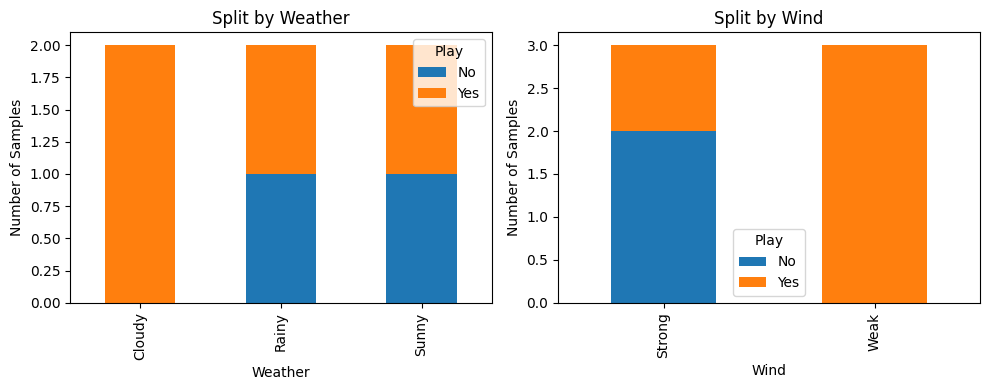

In [4]:
import matplotlib.pyplot as plt

weather_counts = pd.crosstab(df["Weather"], df["Play"])
wind_counts = pd.crosstab(df["Wind"], df["Play"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

weather_counts.plot(kind="bar", stacked=True, ax=axes[0])
axes[0].set_title("Split by Weather")
axes[0].set_xlabel("Weather")
axes[0].set_ylabel("Number of Samples")
axes[0].legend(title="Play")

wind_counts.plot(kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Split by Wind")
axes[1].set_xlabel("Wind")
axes[1].set_ylabel("Number of Samples")
axes[1].legend(title="Play")

plt.tight_layout()
plt.show()

In [6]:
ig_weather = information_gain(df, "Weather", "Play")
ig_wind = information_gain(df, "Wind", "Play")

print(f"Information Gain - Weather: {ig_weather:.3f}")
print(f"Information Gain - Wind: {ig_wind:.3f}")

if ig_weather > ig_wind:
    print("Best split: Weather")
else:
    print("Best split: Wind")

[0.33333333 0.66666667]
[0.5 0.5]
[0.5 0.5]
[1.]
[0.33333333 0.66666667]
[1.]
[0.66666667 0.33333333]
Information Gain - Weather: 0.252
Information Gain - Wind: 0.459
Best split: Wind


## Data Loading

#### Two Moons Dataset

- Contains 400 synthetic samples forming two interleaving half-moon shapes.
- Each sample has 2 features representing its coordinates in a 2D feature space.

In [7]:
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt

X, y = make_moons(
    n_samples=400,
    noise=0.30,
    random_state=1231
)

X shape: (400, 2)
y shape: (400,)


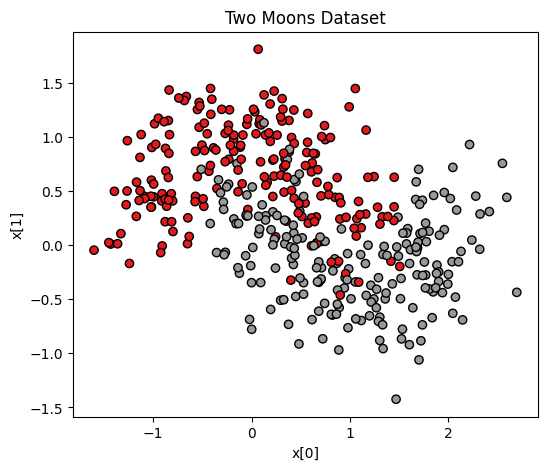

In [8]:
print("X shape:", X.shape)
print("y shape:", y.shape)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Set1, edgecolor="k")
plt.title("Two Moons Dataset")
plt.xlabel("x[0]")
plt.ylabel("x[1]")
plt.show()

## Train - Val - Test Split

We will split the dataset into training, validation, and test sets with proportions of 70%, 15%, and 15%, respectively.

In [9]:
from sklearn.model_selection import train_test_split

# first split: Train (70%) vs Temp (30%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=1231)

# second split: Val (15%) vs Test (15%)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=1231)

In [10]:
print("Training data shape")
print("Features:", X_train.shape, "Labels", y_train.shape)
print("\nValidation data shape")
print("Features:", X_val.shape, "Labels", y_val.shape)
print("\nTest data shape")
print("Features:", X_test.shape, "Labels", y_test.shape)

Training data shape
Features: (280, 2) Labels (280,)

Validation data shape
Features: (60, 2) Labels (60,)

Test data shape
Features: (60, 2) Labels (60,)


## Build a Decision Tree

We will first train a simple decision tree using **entropy** as the splitting criterion, connecting the implementation to the entropy and information gain calculations we used above.

In [11]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=3,
    random_state=1231
)

tree.fit(X_train, y_train)



DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1231)

Visualize the decision tree

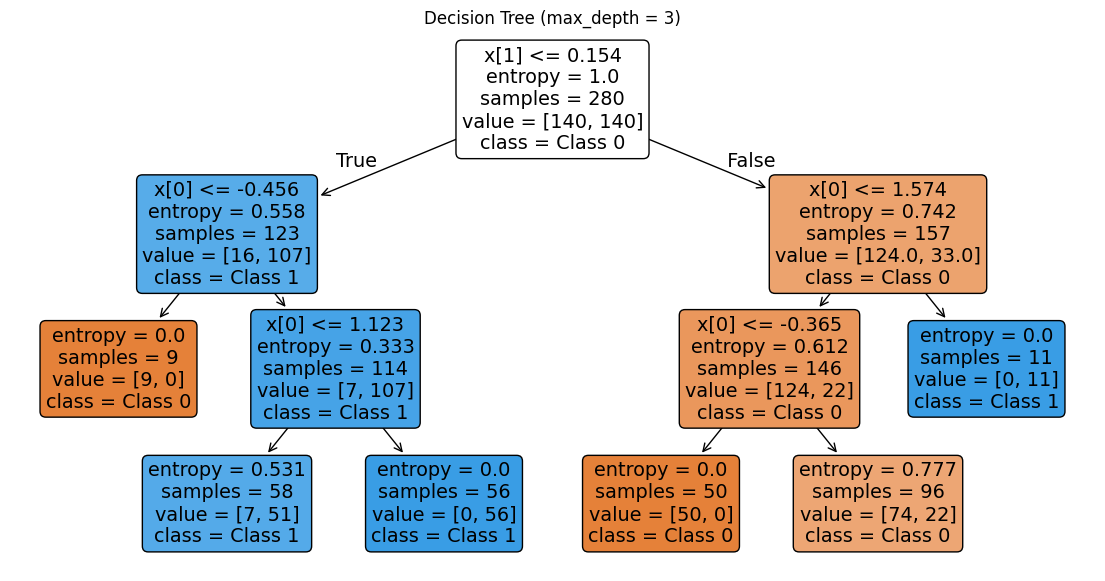

In [12]:
from sklearn.tree import plot_tree

plt.figure(figsize=(14, 7))

plot_tree(
    tree,
    filled=True,
    feature_names=["x[0]", "x[1]"],
    class_names=["Class 0", "Class 1"],
    rounded=True
)

plt.title("Decision Tree (max_depth = 3)")
plt.show()

## Decision Boundary

Since a decision tree splits continuous features using threshold decisions, we can visualize how these splits divide the feature space into different prediction regions.

In [13]:
def plot_decision_boundary(model, X, y):
    x0_min, x0_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x1_min, x1_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x0_min, x0_max, 300),
        np.linspace(x1_min, x1_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    predictions = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, predictions, alpha=0.3, cmap=plt.cm.Set1)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Set1, edgecolor="k")

    plt.xlabel("x[0]")
    plt.ylabel("x[1]")
    plt.title("Decision Boundary")
    plt.show()

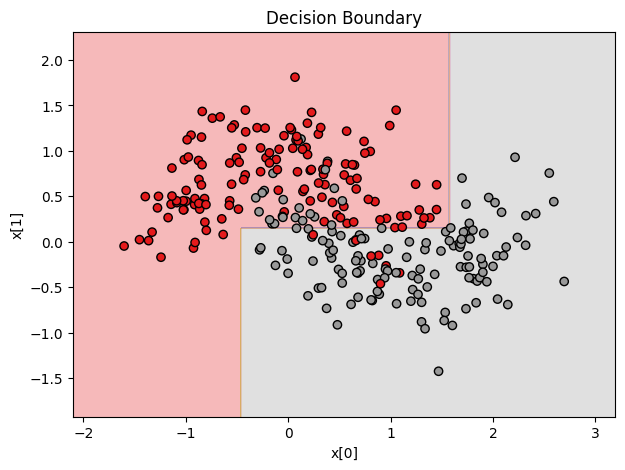

In [14]:
plot_decision_boundary(tree, X_train, y_train)

## Underfitting vs Overfitting

Let's compare decision trees with different depths and observe how model complexity affects training and validation performance.

- **Underfitting** occurs when the model is too simple to capture the underlying patterns in the data. In this case, both training and validation performance are usually poor.

- **Overfitting** occurs when the model becomes too complex and starts fitting the specific details or noise in the training data. Training performance may become very high, while validation performance gets worse.

- A well-generalizing model should be complex enough to learn the important patterns, but not so complex that it memorizes the training data.

For decision trees, increasing `max_depth` increases model complexity, so it provides a useful way to observe the transition from underfitting to overfitting.

In [15]:
from sklearn.metrics import accuracy_score

depths = list(range(1, 11)) + [None]

models = {}
train_errors = []
val_errors = []

for depth in depths:
    model = DecisionTreeClassifier(
        criterion="entropy",
        max_depth=depth,
        random_state=1231
    )

    model.fit(X_train, y_train)
    models[depth] = model

    train_acc = model.score(X_train, y_train)
    val_acc = model.score(X_val, y_val)

    train_errors.append(1 - train_acc)
    val_errors.append(1 - val_acc)

    print(f"max_depth = {depth}")
    print(f"Training Accuracy:   {train_acc:.3f}")
    print(f"Validation Accuracy: {val_acc:.3f}")
    print()

max_depth = 1
Training Accuracy:   0.825
Validation Accuracy: 0.800

max_depth = 2
Training Accuracy:   0.896
Validation Accuracy: 0.850

max_depth = 3
Training Accuracy:   0.896
Validation Accuracy: 0.850

max_depth = 4
Training Accuracy:   0.896
Validation Accuracy: 0.850

max_depth = 5
Training Accuracy:   0.929
Validation Accuracy: 0.850

max_depth = 6
Training Accuracy:   0.943
Validation Accuracy: 0.783

max_depth = 7
Training Accuracy:   0.954
Validation Accuracy: 0.817

max_depth = 8
Training Accuracy:   0.975
Validation Accuracy: 0.800

max_depth = 9
Training Accuracy:   0.982
Validation Accuracy: 0.783

max_depth = 10
Training Accuracy:   0.993
Validation Accuracy: 0.767

max_depth = None
Training Accuracy:   1.000
Validation Accuracy: 0.767



Now, let's visualize how training and validation errors change as the tree becomes more complex.

As `max_depth` increases, the training error is expected to decrease. However, if the tree becomes too complex, the validation error may start increasing, indicating overfitting.

`max_depth=None` represents a tree with no explicit depth restriction.

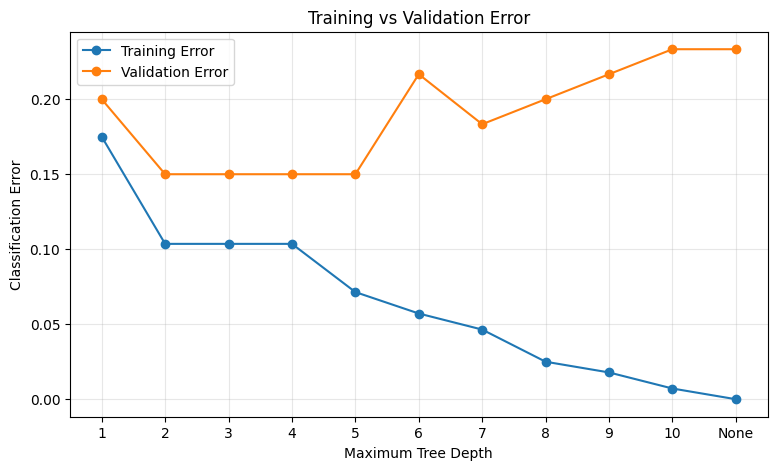

In [16]:
depth_labels = [str(depth) for depth in depths]
x_positions = range(len(depths))

plt.figure(figsize=(9, 5))

plt.plot(
    x_positions,
    train_errors,
    marker="o",
    label="Training Error"
)

plt.plot(
    x_positions,
    val_errors,
    marker="o",
    label="Validation Error"
)

plt.xticks(x_positions, depth_labels)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Classification Error")
plt.title("Training vs Validation Error")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

Finally, let's compare the decision boundaries learned by trees with different levels of complexity.

Instead of visualizing every depth, we select a few representative values.

max_depth = 1


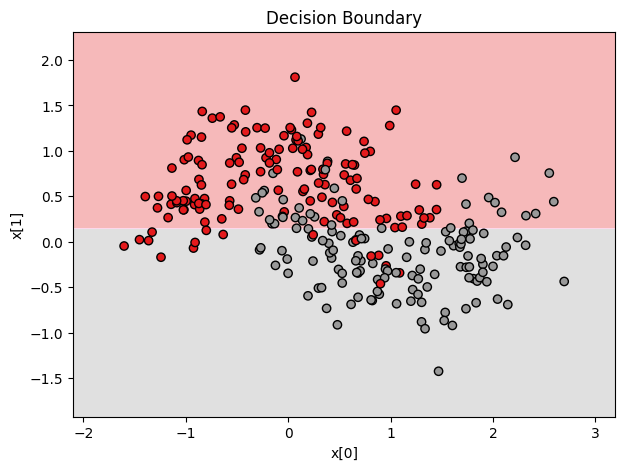

max_depth = 3


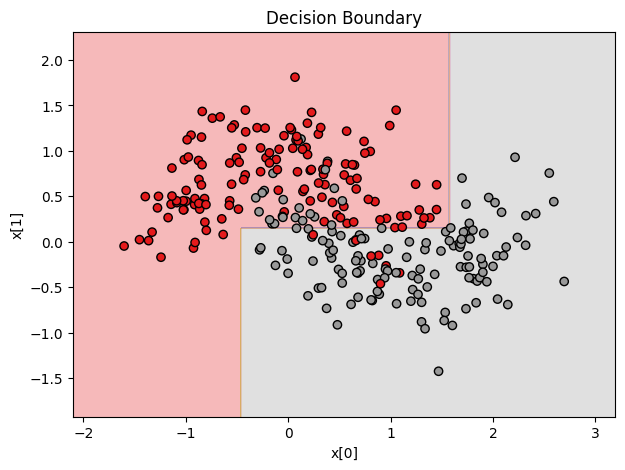

max_depth = 5


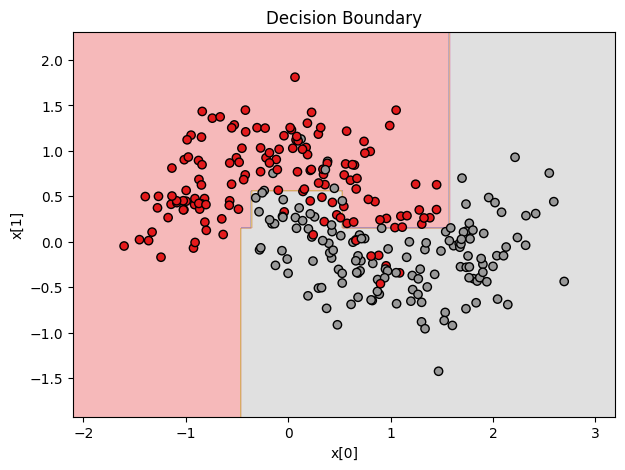

max_depth = 7


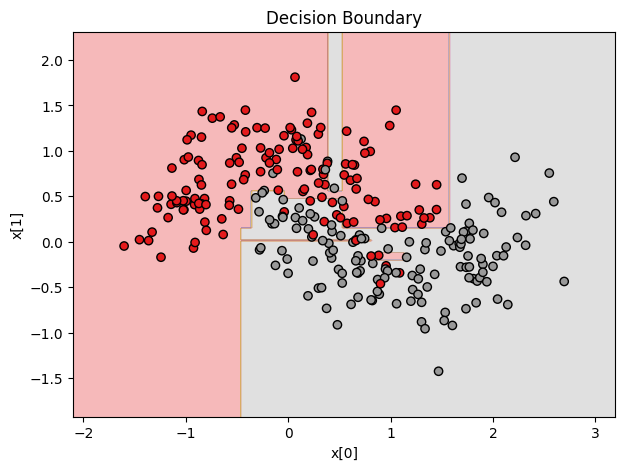

max_depth = None


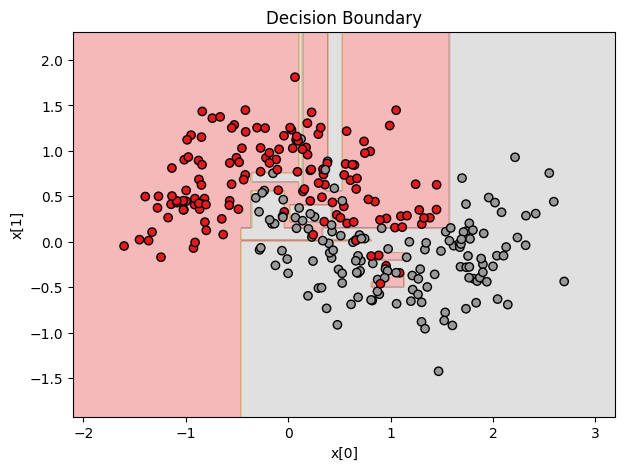

In [17]:
boundary_depths = [1, 3, 5, 7, None]

for depth in boundary_depths:
    print(f"max_depth = {depth}")
    plot_decision_boundary(models[depth], X_train, y_train)

## Hyperparameter Selection

Using the validation set, we will select the hyperparameters that give the best validation performance.

We will consider:

- `max_depth`: controls the maximum depth of the tree.
- `min_samples_split`: controls the minimum number of samples required to split an internal node.

The test set will not be used during hyperparameter selection.

In [18]:
max_depth_values = list(range(1, 11)) + [None]
min_samples_split_values = [2, 5, 10]

best_params = None
best_accuracy = 0

for depth in max_depth_values:
    for split in min_samples_split_values:

        model = DecisionTreeClassifier(
            criterion="entropy",
            max_depth=depth,
            min_samples_split=split,
            random_state=1231
        )

        model.fit(X_train, y_train)

        y_val_pred = model.predict(X_val)
        val_accuracy = accuracy_score(y_val, y_val_pred)

        print(
            f"max_depth={depth}, "
            f"min_samples_split={split} -> "
            f"Validation Accuracy: {val_accuracy:.3f}"
        )

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_params = {
                "max_depth": depth,
                "min_samples_split": split
            }

print("\nBest Hyperparameters:", best_params)
print(f"Best Validation Accuracy: {best_accuracy:.3f}")

max_depth=1, min_samples_split=2 -> Validation Accuracy: 0.800
max_depth=1, min_samples_split=5 -> Validation Accuracy: 0.800
max_depth=1, min_samples_split=10 -> Validation Accuracy: 0.800
max_depth=2, min_samples_split=2 -> Validation Accuracy: 0.850
max_depth=2, min_samples_split=5 -> Validation Accuracy: 0.850
max_depth=2, min_samples_split=10 -> Validation Accuracy: 0.850
max_depth=3, min_samples_split=2 -> Validation Accuracy: 0.850
max_depth=3, min_samples_split=5 -> Validation Accuracy: 0.850
max_depth=3, min_samples_split=10 -> Validation Accuracy: 0.850
max_depth=4, min_samples_split=2 -> Validation Accuracy: 0.850
max_depth=4, min_samples_split=5 -> Validation Accuracy: 0.850
max_depth=4, min_samples_split=10 -> Validation Accuracy: 0.850
max_depth=5, min_samples_split=2 -> Validation Accuracy: 0.850
max_depth=5, min_samples_split=5 -> Validation Accuracy: 0.850
max_depth=5, min_samples_split=10 -> Validation Accuracy: 0.850
max_depth=6, min_samples_split=2 -> Validation Acc

## Final Model & Evaluation

After selecting the best hyperparameters using the validation set, we combine the training and validation sets and train the final model.

The test set is used only once, at the end, to evaluate the final model on unseen data.

In [19]:
X_train_final = np.concatenate((X_train, X_val), axis=0)
y_train_final = np.concatenate((y_train, y_val), axis=0)

print("Final training data shape:", X_train_final.shape)
print("Final training labels shape:", y_train_final.shape)

Final training data shape: (340, 2)
Final training labels shape: (340,)


In [20]:
final_model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=best_params["max_depth"],
    min_samples_split=best_params["min_samples_split"],
    random_state=1231
)

final_model.fit(X_train_final, y_train_final)

DecisionTreeClassifier(criterion='entropy', max_depth=2, random_state=1231)

In [21]:
y_test_pred = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Test Accuracy: {test_accuracy:.3f}")

Test Accuracy: 0.867


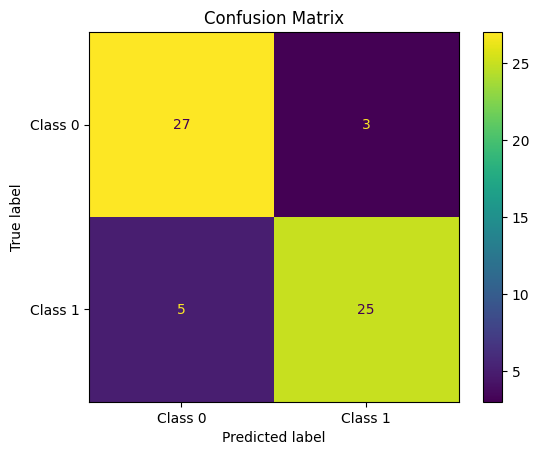

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Class 0", "Class 1"]
)

plt.title("Confusion Matrix")
plt.show()

Finally, let's visualize the learned decision tree.

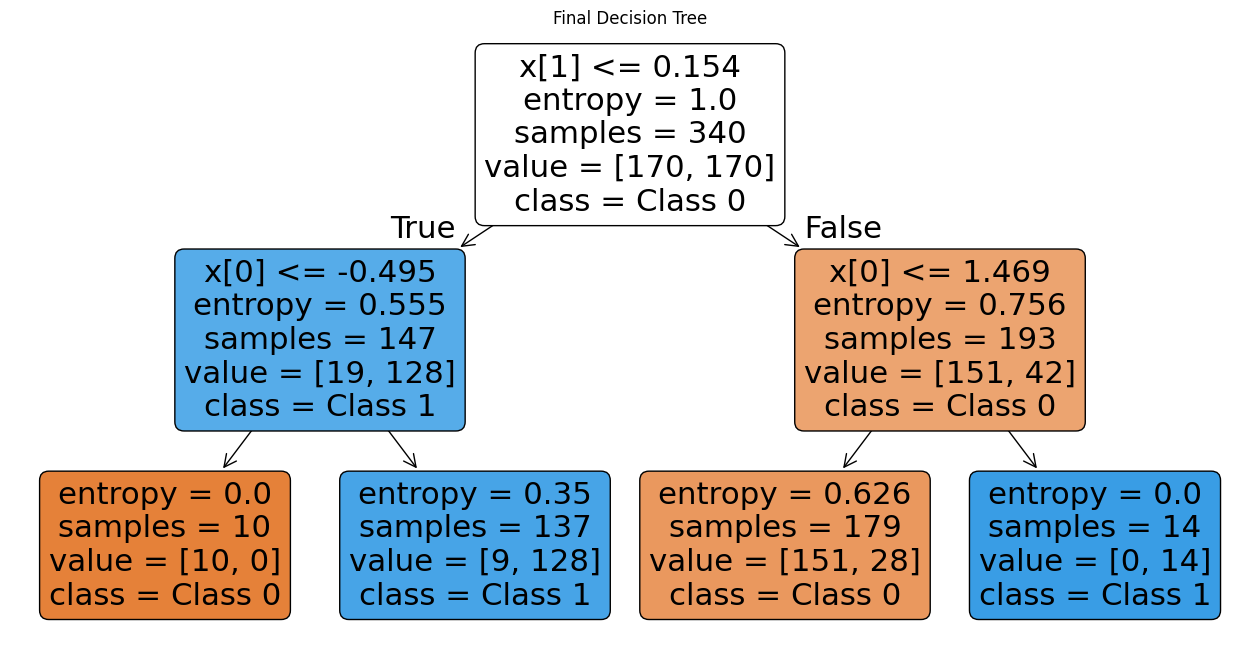

In [23]:
plt.figure(figsize=(16, 8))

plot_tree(
    final_model,
    filled=True,
    feature_names=["x[0]", "x[1]"],
    class_names=["Class 0", "Class 1"],
    rounded=True
)

plt.title("Final Decision Tree")
plt.show()